# CSHELL science: He 10830 atmospheres, Paschen-beta accretion, and NIR radial velocities

CSHELL is a bright-object, single-order instrument: 1.08 to 1.75 um at R = 18,000 to 43,000, but
one setting is only 27 to 44 A wide (FSR about 2.5e-3 of the wavelength). The science that fits is
a single strong line per setting. Three cases are quantified here versus the array size:

1. He I 10830 transmission spectroscopy of transiting planets (escaping atmospheres).
2. Paschen-beta (1282 nm) accretion monitoring of T Tauri stars (nightly to hourly cadence).
3. km/s radial velocities at 1.55 um for Gaia astrometric and eclipsing binaries.

Assumptions: as in notebook 05 for He 10830 (0.7 A FWHM line, 300 s exposures, 2 h transit, equal
out-of-transit time, resel-averaged line core, placeholder slit throughput 0.5 at R = 43k).
Pa-beta: R = 18k, SNR 30 per resel for a 10% line-flux measurement of a line with EW ~ 5 A. RVs:
a photon-only Bouchy et al. (2001) bound over one 40 A setting at R = 43k with an assumed
quality factor, set below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
from pathlib import Path
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = Path("../memo/figures")          # memo figures land here if the directory exists
def save(fig, name):
    if FIG.is_dir():
        fig.savefig(FIG / name)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def mark_scales(ax):
    for n in (20, 200, 1720):
        ax.axvline(n, color='0.6', ls='--', lw=0.8)
    ax.set_xscale('log'); ax.set_xlabel("Number of telescopes")
    equivalent_diameter_axis(ax, ticks=(3, 5, 10, 20, 30))

In [3]:
from scipy.special import erf
EXP = 300.0; N_IN = int(2*3600/EXP); HE_NM = 1083.3; LINE_FWHM_A = 0.7
N_CORE = {"cshell_r43000": 3, "cshell_r18000": 2}
def he(n, preset="cshell_r43000"):
    return LFASTETC(preset, telescope=tel(n), wavelength_min_nm=1081, wavelength_max_nm=1086)
def core_fraction(etc, n_core):
    sigma = LINE_FWHM_A/2.3548/10; half = n_core*HE_NM/etc.instrument.resolving_power/2
    return sigma*np.sqrt(2*np.pi)/(2*half)*erf(half/(sigma*np.sqrt(2)))
def he_sigma(etc, src):
    n_exp = etc.reads_needed(src, EXP)
    snr = etc.snr(src, EXP, n_exp=n_exp).at(HE_NM)["snr"]
    n_core = N_CORE[etc.instrument.name]
    return np.sqrt(2)/(snr*np.sqrt(n_core*N_IN))/core_fraction(etc, n_core)   # sigma on the peak depth

## He 10830: faintest host for a 5 sigma single-transit detection

 0.5% line: N=20: J<5.8  N=200: J<7.8  N=1720: J<9.2
 1.0% line: N=20: J<7.0  N=200: J<8.8  N=1720: J<10.0
 3.0% line: N=20: J<8.5  N=200: J<10.0  N=1720: J<11.2


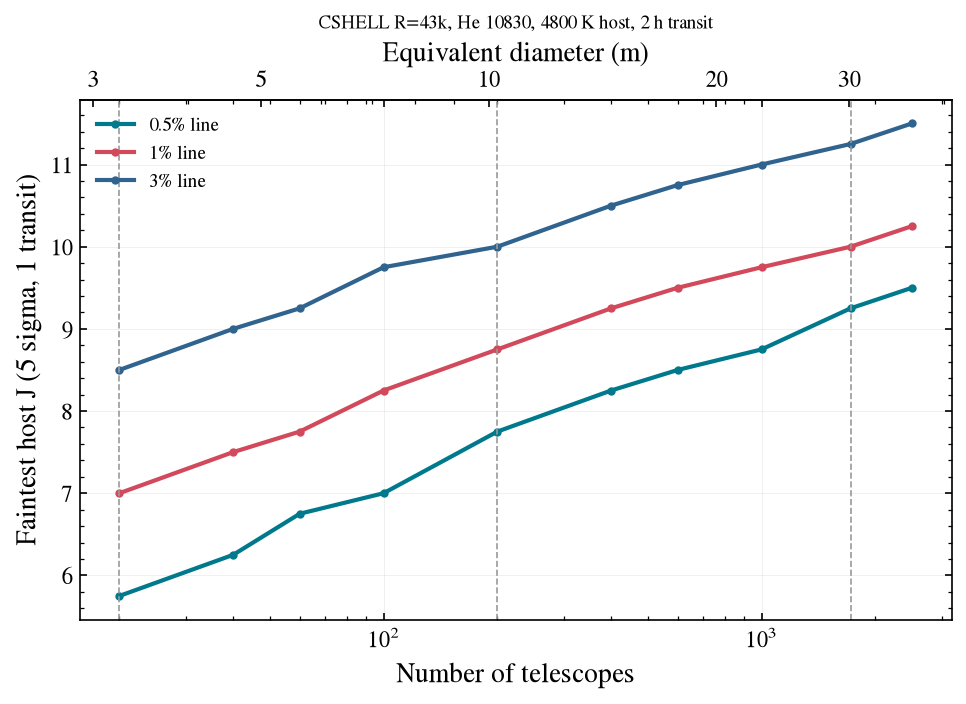

In [4]:
jmags = np.linspace(4, 15, 45)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
reach = {}
for depth, color in ((0.005, 'C0'), (0.01, 'C1'), (0.03, 'C3')):
    lim = []
    for n in NS:
        etc = he(int(n))
        sig = np.array([he_sigma(etc, Source.blackbody(4800, j, "J")) for j in jmags])
        ok = jmags[depth/sig >= 5]
        lim.append(ok.max() if len(ok) else np.nan)
    reach[depth] = dict(zip(NS, lim))
    ax.plot(NS, lim, marker='o', ms=3, color=color, label=f"{100*depth:g}% line")
ax.set_ylabel("Faintest host J (5 sigma, 1 transit)")
ax.set_title("CSHELL R=43k, He 10830, 4800 K host, 2 h transit", fontsize=9); ax.legend()
mark_scales(ax)
save(fig, "he10830_reach_vs_N.pdf")
for depth, d in reach.items():
    print(f"{100*depth:4.1f}% line: " + "  ".join(f"N={n}: J<{d[n]:.1f}" for n in (20, 200, 1720)))

## Paschen-beta accretion monitoring of T Tauri stars (Taurus, 140 pc: J ~ 8 to 12)

In [5]:
def pab(n):
    return LFASTETC("cshell_r18000", telescope=tel(n), wavelength_min_nm=1280, wavelength_max_nm=1284)
for n in (20, 200, 1720):
    e = pab(n)
    t = e.exptime_vs_mag(Source.blackbody(4000, 0, "J"), [8, 10, 12, 14], snr=30, wavelength=1282.2)
    print(f"N={n:5d}: " + "  ".join(f"J={m}: {ti:7.0f} s" for m, ti in zip((8, 10, 12, 14), t)))

N=   20: J=8:      26 s  J=10:     249 s  J=12:    5823 s  J=14:  214991 s
N=  200: J=8:       6 s  J=10:      47 s  J=12:     652 s  J=14:   21585 s
N= 1720: J=8:       2 s  J=10:      13 s  J=12:     118 s  J=14:    2591 s


## Radial velocities at 1.55 um, R = 43,000

Photon-limited RV precision scales as $\sigma_{RV} = c / (Q \sqrt{N_{e}})$ (Bouchy et al. 2001)
with $N_e$ the total electrons in the spectrum and $Q$ the spectral quality factor. For a K or M
dwarf at R = 43k in a 40 A window in the H band (one CSHELL setting) we take $Q$ = 300. Bouchy
et al. give Q ~ 10$^4$ at R = 100k across the full optical range, and a 40 A window with few
lines is far poorer, so $Q$ is the knob to revisit.

This is a photon-only bound with an assumed $Q$: $N_e$ counts source electrons only (no sky,
dark or read noise enters), and a blackbody carries no line information, so the number is only
as good as $Q$. The result is a scaling: km/s orbits for binaries are easy, m/s planet work is not.

In [6]:
Q = 300.0
RV_WINDOW_A = 40; RV_START_NM = 1550.0                      # one CSHELL setting, 40 A wide
def rv(n):
    return LFASTETC("cshell_r43000", telescope=tel(n), wavelength_min_nm=RV_START_NM,
                    wavelength_max_nm=RV_START_NM + RV_WINDOW_A/10)
for n in (20, 200, 1720):
    e = rv(n); row = []
    for h in (6, 9, 12):
        src = Source.blackbody(4000, h, "H")
        r = e.snr(src, 900, n_exp=e.reads_needed(src, 900))
        ne = np.nansum(r.n_star*r.exptime)        # source electrons across the 40 A window
        row.append(f"H={h}: {2.998e5/(Q*np.sqrt(ne)):7.2f} km/s")
    print(f"N={n:5d} (15 min, photon-only, Q assumed): " + "  ".join(row))

N=   20 (15 min, photon-only, Q assumed): H=6:    0.37 km/s  H=9:    1.48 km/s  H=12:    5.90 km/s
N=  200 (15 min, photon-only, Q assumed): H=6:    0.12 km/s  H=9:    0.47 km/s  H=12:    1.87 km/s
N= 1720 (15 min, photon-only, Q assumed): H=6:    0.04 km/s  H=9:    0.16 km/s  H=12:    0.64 km/s


## Bright end: reads needed for a J = 3 star in 300 s (placeholder 80 ke- full well)

In [7]:
for n in (20, 200, 1720):
    print(f"N={n:5d}: reads = {he(n, 'cshell_r18000').reads_needed(Source.blackbody(4800, 3, 'J'), 300)}")

N=   20: reads = 8


N=  200: reads = 8
N= 1720: reads = 8
